# Tarea 2 · ¿Cesárea o parto vaginal? Nacimientos en el Hospital General de Medellín

Primer análisis en Google Colab: **leer → parsear → depurar → graficar → predecir**, sobre una base distinta a los hurtos.

## Dataset

- **Nombre:** Nacimientos ocurridos en el Hospital General de Medellín
- **Fuente:** datos.gov.co (Hospital General de Medellín, datos abiertos). Ficha: <https://www.datos.gov.co/d/kjs7-2ryw>
- **Lectura:** directo desde la API pública (opción B de la guía), sin subir archivos ni depender de rutas locales.
- **Tamaño después de leer:** 22 234 filas y 32 columnas (se verifica en la celda 1). Cobertura: enero de 2022 a septiembre de 2026. **Un registro = un nacimiento.**

## Problema

Dadas las características de la madre, del embarazo y de su aseguramiento, **¿se puede anticipar si el parto terminó en cesárea?**

- **y:** `y_cesarea = 1` si `tipo_parto` es cesárea y `0` si es espontáneo o instrumentado (parto vaginal). Sale de la columna `tipo_parto`.
- **Baseline:** predecir siempre la clase mayoritaria del entrenamiento (parto no cesárea).
- **Split:** temporal. Se entrena con 2022–2024 y se prueba con 2025–2026.
- **Métrica principal:** recall y F1 de la clase cesárea, más matriz de confusión; la exactitud sola no basta.

## 0. Configuración

In [1]:
# En Colab pandas, numpy, matplotlib y scikit-learn ya vienen instalados.
# Si algún import fallara, descomente:
# %pip install scikit-learn

import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay)

SEMILLA = 42
rng = np.random.default_rng(SEMILLA)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Lectura

Se lee con codificación y separador explícitos. El límite de la API (`$limit`) se sube a 50 000 para traer todas las filas (el conjunto tiene unas 22 000).

In [2]:
URL = "https://www.datos.gov.co/resource/kjs7-2ryw.csv?$limit=50000"

crudo = pd.read_csv(URL, sep=",", encoding="utf-8", na_values=["", "NA", "N/A"])
print("Filas y columnas leídas:", crudo.shape)
df = crudo.copy()
crudo.head(3).T

Filas y columnas leídas: (22234, 32)


,0,1,2
ano,2022,2022,2022
periodo_de_reporte,3,3,3
sexo,FEMENINO,MASCULINO,MASCULINO
peso_gramos,2341,3750,3527
talla_centimetros,44,51,51
fecha_nacimiento,2022-01-01T00:00:00.000,2022-01-01T00:00:00.000,2022-01-01T00:00:00.000
parto_atendido_por,MEDICO,MEDICO,MEDICO
tiempo_de_gestacion,37.0,40.0,38.0
numero_consultas_prenatales,7,7,7
tipo_parto,ESPONTANEO,ESPONTANEO,ESPONTANEO


## 2. Limpieza

### 2.1 Auditoría inicial

Primero se mira qué trajo la lectura: tipos, faltantes y duplicados exactos.

In [3]:
auditoria = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "n_unicos": df.nunique(),
    "faltantes": df.isna().sum(),
    "% faltantes": (df.isna().mean() * 100).round(1),
})
print("Duplicados exactos:", df.duplicated().sum())
auditoria.sort_values("% faltantes", ascending=False)

Duplicados exactos: 0


,tipo,n_unicos,faltantes,% faltantes
localidad,str,1572,5683,25.6
nombre_administradora,str,85,2743,12.3
nivel_educativo_padre,str,23,2484,11.2
edad_padre,float64,63,816,3.7
ultimo_ano_aprobado_madre,float64,12,411,1.8
estado_conyugal_madre,str,17,194,0.9
nivel_educativo_madre,str,23,197,0.9
grupo_sanguineo,str,4,126,0.6
factor_rh,str,2,133,0.6
apgar2,float64,10,47,0.2


### 2.2 Parseo de tipos

- `fecha_nacimiento` llega como texto ISO; se convierte a fecha.
- Las columnas que deberían ser numéricas se fuerzan con `errors="coerce"` y se **cuenta cuántos `NaN` nacen** en ese paso: si el parseo inventara huecos, aquí se vería.

In [4]:
# Fecha
n_antes = df["fecha_nacimiento"].isna().sum()
df["fecha_nacimiento"] = pd.to_datetime(df["fecha_nacimiento"], errors="coerce")
print(f"NaN en fecha_nacimiento: antes {n_antes} -> después {df['fecha_nacimiento'].isna().sum()}")

# Numéricas
numericas = ["ano", "periodo_de_reporte", "peso_gramos", "talla_centimetros", "tiempo_de_gestacion",
             "numero_consultas_prenatales", "apgar1", "apgar2", "edad_madre", "ultimo_ano_aprobado_madre",
             "numero_hijos_nacidos_vivos", "numero_embarazos", "edad_padre"]
nacidos = {}
for c in numericas:
    antes = df[c].isna().sum()
    df[c] = pd.to_numeric(df[c], errors="coerce")
    nacidos[c] = df[c].isna().sum() - antes
print("NaN creados por el parseo numérico:", {k: v for k, v in nacidos.items() if v} or "ninguno")

print("Rango de fechas:", df["fecha_nacimiento"].min().date(), "->", df["fecha_nacimiento"].max().date())

NaN en fecha_nacimiento: antes 0 -> después 0
NaN creados por el parseo numérico: ninguno
Rango de fechas: 2022-01-01 -> 2026-09-30


### 2.3 Texto: la misma categoría escrita de dos formas

Una mirada a `tipo_parto` ya delata el problema: aparecen `ESPONTANEO` y `ESPONTÁNEO`, `CESAREA` y `CESÁREA`. Son la misma categoría con y sin tilde (el registro cambió de formato con el tiempo). Si no se unifican, el modelo trataría una cesárea de 2022 y una de 2025 como cosas distintas.

**Decisión:** quitar tildes, pasar a mayúsculas y colapsar espacios en todas las columnas de texto.

In [5]:
print("Antes:", df["tipo_parto"].value_counts().to_dict())

def normalizar(x):
    if pd.isna(x):
        return x
    x = unicodedata.normalize("NFKD", str(x))
    x = "".join(c for c in x if not unicodedata.combining(c))
    return " ".join(x.upper().split())

cols_texto = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c]) and c != "fecha_nacimiento"]
nunicos_antes = {c: df[c].nunique() for c in cols_texto}
for c in cols_texto:
    df[c] = df[c].map(normalizar)

print("Después:", df["tipo_parto"].value_counts().to_dict())
colapso = pd.DataFrame({"antes": nunicos_antes, "después": {c: df[c].nunique() for c in cols_texto}})
colapso[colapso["antes"] != colapso["después"]]

Antes: {'ESPONTANEO': 10507, 'CESAREA': 5593, 'ESPONTÁNEO': 3031, 'CESÁREA': 2137, 'INSTRUMENTADO': 966}


Después: {'ESPONTANEO': 13538, 'CESAREA': 7730, 'INSTRUMENTADO': 966}


,antes,después
parto_atendido_por,6,5
tipo_parto,5,3
pertenencia_etnica,7,6
estado_conyugal_madre,17,13
nivel_educativo_madre,23,14
departamento_residencia,30,25
municipio_residencia,295,229
area_residencia,4,3
localidad,1572,1524
regimen_seguridad,6,5


### 2.4 `estado_conyugal_madre`: cambió la redacción, no solo las tildes

Además de las tildes, la redacción cambió entre periodos (`ESTA SOLTERA` vs `ESTABA SOLTERO(A)`, `NO ESTA CASADA Y LLEVA...` vs `NO ESTABA CASADO(A) Y LLEVABA...`). Se mapean a 6 categorías comparables.

In [6]:
def mapear_estado(x):
    if pd.isna(x):
        return np.nan
    if "SOLTER" in x:
        return "SOLTERA"
    if x.startswith("NO EST"):
        if "MENOS DE DOS" in x:
            return "UNION LIBRE < 2 ANOS"
        if "DOS ANOS O MAS" in x:
            return "UNION LIBRE >= 2 ANOS"
    if "CASAD" in x:
        return "CASADA"
    if "SEPARAD" in x:
        return "SEPARADA"
    if "VIUD" in x:
        return "VIUDA"
    return np.nan if "SIN INFORMACION" in x else x

print("Categorías antes:", df["estado_conyugal_madre"].nunique())
df["estado_conyugal_madre"] = df["estado_conyugal_madre"].map(mapear_estado)
print("Categorías después:", df["estado_conyugal_madre"].nunique())
df["estado_conyugal_madre"].value_counts(dropna=False)

Categorías antes: 13
Categorías después: 6


estado_conyugal_madre
UNION LIBRE >= 2 ANOS    10596
UNION LIBRE < 2 ANOS      4868
SOLTERA                   4492
CASADA                    1947
NaN                        277
SEPARADA                    31
VIUDA                       23
Name: count, dtype: int64

### 2.5 `Sin información` no es una categoría: es un faltante

Los textos `SIN INFORMACION` se convierten en `NaN`. Dejarlos como categoría haría que el modelo aprendiera “no hay dato” como si fuera un grupo de madres.

In [7]:
sentinelas = df[cols_texto].eq("SIN INFORMACION").sum()
print("Celdas 'SIN INFORMACION' por columna:", sentinelas[sentinelas > 0].to_dict())
df[cols_texto] = df[cols_texto].replace("SIN INFORMACION", np.nan)

Celdas 'SIN INFORMACION' por columna: {'nivel_educativo_madre': 77, 'nivel_educativo_padre': 127}


### 2.6 Valores imposibles o sospechosos

| Regla | Qué se hace | Por qué |
| --- | --- | --- |
| `edad_padre > 80` | se pasa a `NaN` | 94, 99 y 100 años son errores de digitación; 75–76 sí son plausibles y se dejan |
| `edad_madre` 12–14 años | **se deja** | son casos reales y vulnerables; borrarlos sería ocultar el fenómeno |
| `numero_hijos_nacidos_vivos > numero_embarazos` en embarazo simple | se **marca** (`paridad_inconsistente`), no se borra | es inconsistente en pocos casos y no se sabe cuál de los dos campos falla |
| peso < 1000 g, gestación < 28 sem | se **dejan** | extremos coherentes entre sí (prematuros extremos) |
| consultas prenatales > 20 | se dejan | altas pero posibles en embarazos de riesgo |

No se elimina ninguna fila solo por estorbar en un gráfico o en el modelo.

In [8]:
imposibles_padre = (df["edad_padre"] > 80).sum()
df.loc[df["edad_padre"] > 80, "edad_padre"] = np.nan
print("edad_padre > 80 pasada a NaN:", imposibles_padre)

df["paridad_inconsistente"] = (df["numero_hijos_nacidos_vivos"] > df["numero_embarazos"]) & (df["multiplicidad_embarazo"] == "SIMPLE")
print("Paridad inconsistente (marcada, no borrada):", df["paridad_inconsistente"].sum(), f"({df['paridad_inconsistente'].mean():.1%})")

print("Madres de 12-14 años (se dejan):", (df["edad_madre"] < 15).sum())
print("Gestación < 28 semanas:", (df["tiempo_de_gestacion"] < 28).sum(), "| peso < 1000 g:", (df["peso_gramos"] < 1000).sum())

edad_padre > 80 pasada a NaN: 3
Paridad inconsistente (marcada, no borrada): 133 (0.6%)
Madres de 12-14 años (se dejan): 191
Gestación < 28 semanas: 115 | peso < 1000 g: 142


### 2.7 Faltantes: qué se hace con cada columna

El patrón de `localidad` es informativo: casi solo se llena para residentes de Medellín (el hueco es **estructural**, no un olvido).

In [9]:
es_medellin = df["municipio_residencia"] == "MEDELLIN"
print("localidad vacía entre residentes de Medellín:", f"{df.loc[es_medellin, 'localidad'].isna().mean():.1%}")
print("localidad vacía fuera de Medellín:", f"{df.loc[~es_medellin, 'localidad'].isna().mean():.1%}")

faltantes = (df.isna().mean() * 100).round(1)
faltantes[faltantes > 0].sort_values(ascending=False).to_frame("% faltante")

localidad vacía entre residentes de Medellín: 5.3%
localidad vacía fuera de Medellín: 51.2%


,% faltante
localidad,25.6
nombre_administradora,12.3
nivel_educativo_padre,11.7
edad_padre,3.7
ultimo_ano_aprobado_madre,1.8
nivel_educativo_madre,1.2
estado_conyugal_madre,1.2
grupo_sanguineo,0.6
factor_rh,0.6
apgar2,0.2


| Columna | % faltante aprox. | Decisión | Por qué |
| --- | --- | --- | --- |
| `localidad` | ~26 % | **no se imputa ni se usa** | hueco estructural (solo aplica a residentes de Medellín); imputar inventaría localidades |
| `nombre_administradora` | ~12 % | no se usa | es una etiqueta de aseguradora; `regimen_seguridad` ya cubre la idea |
| `nivel_educativo_padre`, `edad_padre` | ~12 % y ~4 % | se **imputan dentro del Pipeline** (moda / mediana del entrenamiento) | pocos faltantes; imputar con estadísticos del tren evita filtrar la prueba |
| `ultimo_ano_aprobado_madre`, `estado_conyugal_madre`, `nivel_educativo_madre` | 1–2 % | igual: se imputan en el Pipeline | pérdida pequeña, columnas útiles |
| `tiempo_de_gestacion` | < 0,1 % (9 filas) | se imputa en el Pipeline (mediana) | muy pocos casos |
| `area_residencia`, `municipio_residencia` | < 0,1 % (5 filas cada una) | se imputan en el Pipeline (moda) | muy pocos casos |
| `apgar1`, `apgar2`, grupo sanguíneo | < 1 % | se dejan (no entran al modelo) | se conocen **después** del parto |

### 2.8 Duplicados y atípicos

No hay duplicados exactos, pero **tampoco hay un identificador** del nacimiento: dos registros idénticos de gemelos o de dos madres con el mismo perfil serían indistinguibles, así que no se borran filas por “parecerse”. Los atípicos se **conservan** (ver tabla 2.6); lo que sí se acotó fue lo imposible.

In [10]:
print("Duplicados exactos:", df.duplicated().sum())
df[["edad_madre", "edad_padre", "tiempo_de_gestacion", "numero_consultas_prenatales", "peso_gramos"]].describe().round(1)

Duplicados exactos: 0


,edad_madre,edad_padre,tiempo_de_gestacion,numero_consultas_prenatales,peso_gramos
count,22234.0,21415.0,22225.0,22234.0,22234.0
mean,25.5,29.6,37.8,6.8,2922.7
std,6.4,7.8,2.2,3.1,564.7
min,12.0,13.0,24.0,0.0,430.0
25%,21.0,24.0,37.0,5.0,2610.0
50%,24.0,28.0,38.0,7.0,2980.0
75%,30.0,34.0,39.0,9.0,3295.0
max,49.0,76.0,42.0,25.0,5200.0


## 3. Gráficos

Cada título es una pregunta. Primero se define `y` y se prepara la variable de tiempo.

In [11]:
df["y_cesarea"] = (df["tipo_parto"] == "CESAREA").astype(int)
df["trimestre"] = df["fecha_nacimiento"].dt.to_period("Q").dt.to_timestamp()

print(df["tipo_parto"].value_counts())
print(f"Proporción de cesáreas en todo el conjunto: {df['y_cesarea'].mean():.1%}")

tipo_parto
ESPONTANEO       13538
CESAREA           7730
INSTRUMENTADO      966
Name: count, dtype: int64
Proporción de cesáreas en todo el conjunto: 34.8%


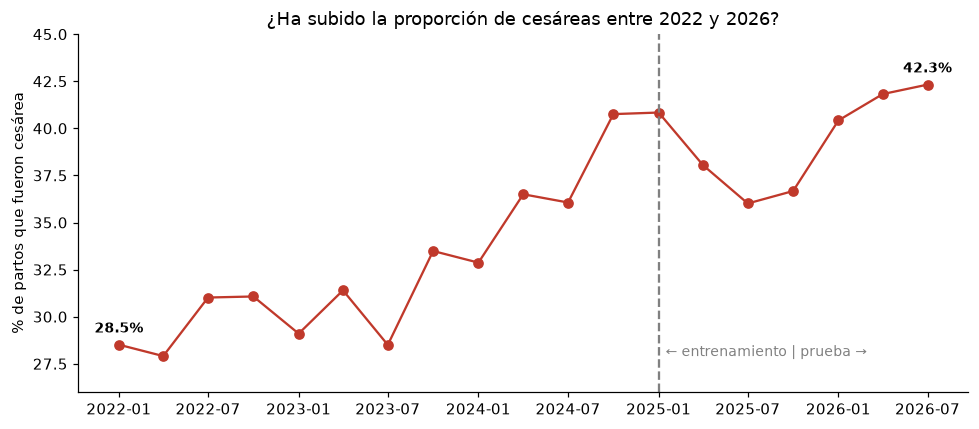

In [12]:
# G1. ¿Ha subido la proporción de cesáreas entre 2022 y 2026?
por_trim = df.groupby("trimestre")["y_cesarea"].agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(por_trim.index, por_trim["mean"] * 100, marker="o", color="#c0392b")
ax.axvline(pd.Timestamp("2025-01-01"), color="grey", ls="--")
ax.text(pd.Timestamp("2025-01-15"), por_trim["mean"].min() * 100, "← entrenamiento | prueba →", color="grey", fontsize=9)
for i in [0, len(por_trim) - 1]:
    ax.annotate(f"{por_trim['mean'].iloc[i]:.1%}", (por_trim.index[i], por_trim["mean"].iloc[i] * 100),
                textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9, fontweight="bold")
ax.set_ylim(26, 45)
ax.set_ylabel("% de partos que fueron cesárea")
ax.set_title("¿Ha subido la proporción de cesáreas entre 2022 y 2026?")
plt.tight_layout(); plt.show()

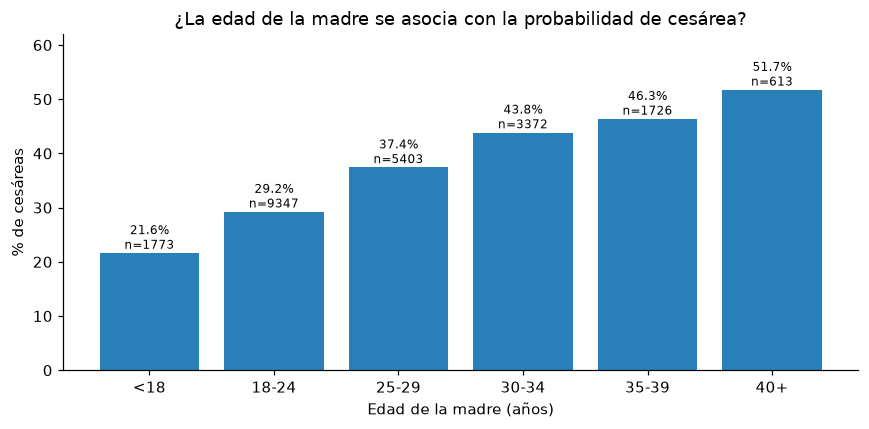

In [13]:
# G2. ¿La edad de la madre se asocia con la probabilidad de cesárea?
bins = [0, 17, 24, 29, 34, 39, 100]
etiquetas = ["<18", "18-24", "25-29", "30-34", "35-39", "40+"]
df["grupo_edad_madre"] = pd.cut(df["edad_madre"], bins=bins, labels=etiquetas)
g = df.groupby("grupo_edad_madre", observed=True)["y_cesarea"].agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(g.index.astype(str), g["mean"] * 100, color="#2980b9")
for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
    ax.text(i, m * 100 + 0.8, f"{m:.1%}\nn={n}", ha="center", fontsize=8)
ax.set_ylim(0, 62)
ax.set_ylabel("% de cesáreas"); ax.set_xlabel("Edad de la madre (años)")
ax.set_title("¿La edad de la madre se asocia con la probabilidad de cesárea?")
plt.tight_layout(); plt.show()

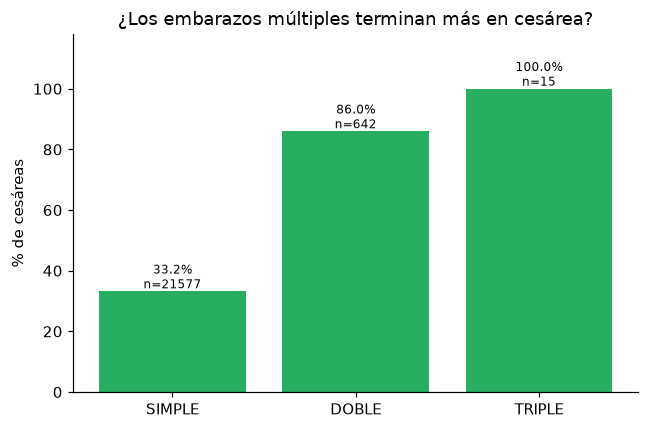

In [14]:
# G3. ¿Los embarazos múltiples terminan más en cesárea?
g = df.groupby("multiplicidad_embarazo")["y_cesarea"].agg(["mean", "size"]).reindex(["SIMPLE", "DOBLE", "TRIPLE"])
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(g.index, g["mean"] * 100, color="#27ae60")
for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
    ax.text(i, m * 100 + 1, f"{m:.1%}\nn={n}", ha="center", fontsize=8)
ax.set_ylabel("% de cesáreas"); ax.set_ylim(0, 118)
ax.set_title("¿Los embarazos múltiples terminan más en cesárea?")
plt.tight_layout(); plt.show()

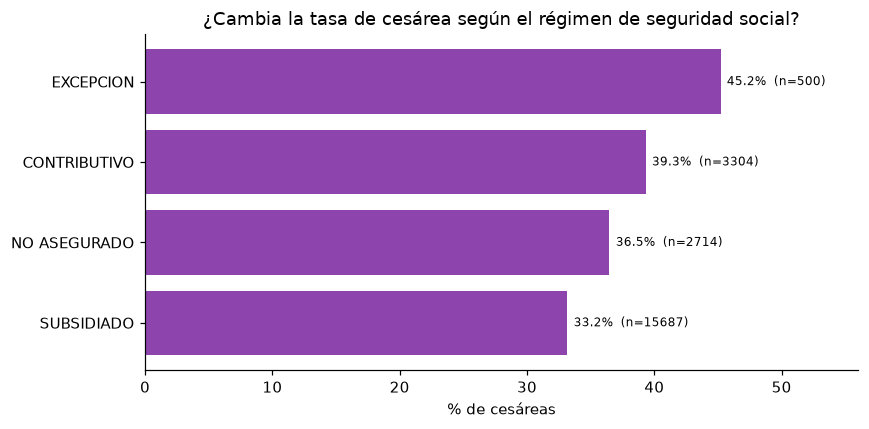

In [15]:
# G4. ¿Cambia la tasa de cesárea según el régimen de seguridad social?
g = df.groupby("regimen_seguridad")["y_cesarea"].agg(["mean", "size"]).sort_values("mean")
g = g[g["size"] >= 100]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(g.index, g["mean"] * 100, color="#8e44ad")
for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
    ax.text(m * 100 + 0.5, i, f"{m:.1%}  (n={n})", va="center", fontsize=8)
ax.set_xlim(0, 56)
ax.set_xlabel("% de cesáreas")
ax.set_title("¿Cambia la tasa de cesárea según el régimen de seguridad social?")
plt.tight_layout(); plt.show()

## 4. Predicción

### 4.1 Contrato científico

- **y:** `y_cesarea`, definida en la sección 3. Se predice si el parto terminó en cesárea.
- **X (qué entra):** variables que se conocen *antes o durante* el trabajo de parto y no definen la respuesta.

| Variable | Decisión | Motivo |
| --- | --- | --- |
| `edad_madre`, `edad_padre`, `tiempo_de_gestacion`, `numero_consultas_prenatales`, `numero_embarazos`, `numero_hijos_nacidos_vivos`, `ultimo_ano_aprobado_madre` | entra (numéricas) | perfil de la madre y del embarazo |
| `multiplicidad_embarazo`, `estado_conyugal_madre`, `nivel_educativo_madre`, `nivel_educativo_padre`, `regimen_seguridad`, `area_residencia`, `municipio_residencia` | entra (categóricas) | contexto socioeconómico y de residencia |
| `peso_gramos`, `talla_centimetros`, `apgar1`, `apgar2` | **fuera** | se miden **después** del nacimiento: filtración |
| `parto_atendido_por`, `profesion_certificador` | **fuera** | describen el acto del parto, no el contexto previo |
| `tipo_parto` | **fuera** | es y |
| `ano`, `periodo_de_reporte`, `fecha_nacimiento` | **fuera** | con un split temporal, usar el año obligaría al modelo a extrapolar |
| `localidad`, `nombre_administradora`, `grupo_sanguineo`, `factor_rh`, `pertenencia_etnica`, `pais_residencia`, `departamento_residencia` | fuera | faltantes estructurales, redundantes o casi constantes |

Una advertencia: `tiempo_de_gestacion` es la edad gestacional **al nacer**. Es razonable como predictor (se conoce en el momento del parto y una cesárea programada suele adelantar el nacimiento), pero la decisión de cesárea y la fecha del parto no son totalmente independientes.

In [16]:
num = ["edad_madre", "edad_padre", "tiempo_de_gestacion", "numero_consultas_prenatales",
       "numero_embarazos", "numero_hijos_nacidos_vivos", "ultimo_ano_aprobado_madre"]
cat = ["multiplicidad_embarazo", "estado_conyugal_madre", "nivel_educativo_madre",
       "nivel_educativo_padre", "regimen_seguridad", "area_residencia", "municipio_residencia"]

corte = pd.Timestamp("2025-01-01")
tr = df[df["fecha_nacimiento"] < corte]
te = df[df["fecha_nacimiento"] >= corte]
X_tr, y_tr = tr[num + cat], tr["y_cesarea"]
X_te, y_te = te[num + cat], te["y_cesarea"]

print(f"Entrenamiento: {len(tr):>6}  ({tr['fecha_nacimiento'].min().date()} a {tr['fecha_nacimiento'].max().date()})  cesárea = {y_tr.mean():.1%}")
print(f"Prueba:        {len(te):>6}  ({te['fecha_nacimiento'].min().date()} a {te['fecha_nacimiento'].max().date()})  cesárea = {y_te.mean():.1%}")

Entrenamiento:  13897  (2022-01-01 a 2024-12-31)  cesárea = 31.9%
Prueba:          8337  (2025-01-01 a 2026-09-30)  cesárea = 39.5%


### 4.1b ¿Qué le hace la imputación a la distribución?

La imputación ocurre dentro del `Pipeline`: la **mediana** (numéricas) y la **moda** (categóricas) se calculan **solo con el entrenamiento**. Aquí se mide cuánto cambia cada variable imputada al rellenar sus huecos (sobre todas las filas).

In [17]:
filas_num, filas_cat = [], []
for c in num:
    s = df[c]
    if s.isna().any():
        valor = tr[c].median()
        r = s.fillna(valor)
        filas_num.append({"variable": c, "imputados": int(s.isna().sum()), "valor (mediana tren)": valor,
                          "media antes": s.mean(), "media después": r.mean(),
                          "desv. antes": s.std(), "desv. después": r.std(),
                          "cambio desv. %": (r.std() / s.std() - 1) * 100})
for c in cat:
    s = df[c]
    if s.isna().any():
        moda = tr[c].mode().iloc[0]
        r = s.fillna(moda)
        filas_cat.append({"variable": c, "imputados": int(s.isna().sum()), "moda (tren)": moda,
                          "% moda antes": (s.dropna() == moda).mean() * 100,
                          "% moda después": (r == moda).mean() * 100})
imp_num = pd.DataFrame(filas_num).set_index("variable").round(3)
imp_cat = pd.DataFrame(filas_cat).set_index("variable").round(2)
print(imp_num.T.to_string()); print(); print(imp_cat.T.to_string())

variable              edad_padre  tiempo_de_gestacion  ultimo_ano_aprobado_madre
imputados                819.000                9.000                    411.000
valor (mediana tren)      28.000               38.000                      9.000
media antes               29.593               37.790                      7.704
media después             29.534               37.790                      7.728
desv. antes                7.823                2.177                      3.193
desv. después              7.684                2.177                      3.168
cambio desv. %            -1.784               -0.020                     -0.778

variable        estado_conyugal_madre      nivel_educativo_madre      nivel_educativo_padre     area_residencia municipio_residencia
imputados                         277                        274                       2611                   5                    5
moda (tren)     UNION LIBRE >= 2 ANOS  MEDIA ACADEMICA O CLASICA  MEDIA ACADEMICA O C

**Lectura.** En las numéricas el efecto es pequeño: la desviación estándar de `edad_padre` baja 1,8 % (7,82 → 7,68), la de `ultimo_ano_aprobado_madre` 0,8 % y la de `tiempo_de_gestacion` casi nada. En las categóricas hay un caso que **sí deforma la distribución**: al rellenar con la moda los 2 611 huecos (11,7 %) de `nivel_educativo_padre`, la categoría *Media académica o clásica* pasa de **35,5 % a 43,1 %**. Es una limitación: cualquier lectura sobre el nivel educativo del padre debe tenerla en cuenta.

### 4.2 Split temporal, pipelines y baseline

Se entrena en el pasado (2022–2024) y se prueba en el futuro (2025–2026). Imputación, escalado y one-hot viven dentro del `Pipeline`, así que se calculan **solo con el entrenamiento**. `municipio_residencia` tiene casi 300 valores; `min_frequency=100` agrupa los municipios raros en una categoría “infrecuente”.

In [18]:
def hacer_prep():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100))]), cat),
    ])

nulo = Pipeline([("prep", hacer_prep()), ("clf", DummyClassifier(strategy="most_frequent"))])
logistica = Pipeline([("prep", hacer_prep()), ("clf", LogisticRegression(max_iter=1000))])
bosque = Pipeline([("prep", hacer_prep()),
                   ("clf", RandomForestClassifier(n_estimators=200, min_samples_leaf=30,
                                                  random_state=SEMILLA, n_jobs=-1))])

modelos = {"Nulo (clase mayoritaria)": nulo, "Regresión logística": logistica, "Bosque aleatorio": bosque}
for m in modelos.values():
    m.fit(X_tr, y_tr)

filas = []
for nombre, m in modelos.items():
    pred = m.predict(X_te)
    filas.append({
        "modelo": nombre,
        "exactitud": accuracy_score(y_te, pred),
        "precisión cesárea": precision_score(y_te, pred, zero_division=0),
        "recall cesárea": recall_score(y_te, pred, zero_division=0),
        "F1 cesárea": f1_score(y_te, pred, zero_division=0),
        "AUC": 0.5 if nombre.startswith("Nulo") else roc_auc_score(y_te, m.predict_proba(X_te)[:, 1]),
    })
resultados = pd.DataFrame(filas).set_index("modelo").round(3)
resultados

,exactitud,precisión cesárea,recall cesárea,F1 cesárea,AUC
modelo,,,,,
Nulo (clase mayoritaria),0.605,0.000,0.000,0.000,0.500
Regresión logística,0.643,0.705,0.165,0.268,0.654
Bosque aleatorio,0.635,0.810,0.102,0.181,0.657


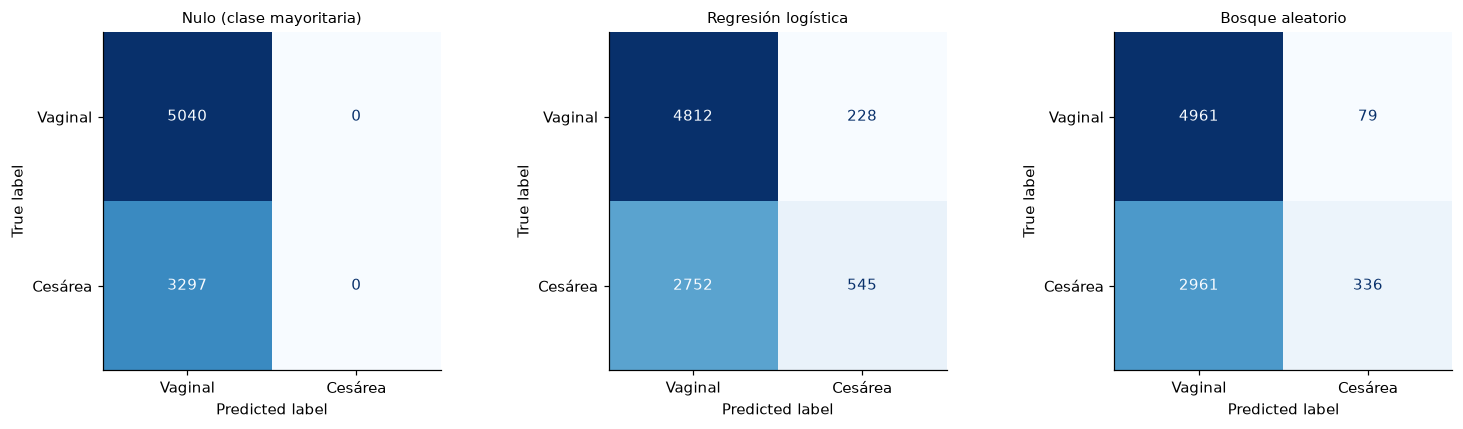

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (nombre, m) in zip(axes, modelos.items()):
    ConfusionMatrixDisplay.from_predictions(y_te, m.predict(X_te), display_labels=["Vaginal", "Cesárea"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(nombre, fontsize=10)
plt.tight_layout(); plt.show()

### 4.3 Interpretación: ¿qué pesa en la logística?

Coeficientes positivos empujan hacia cesárea; negativos, hacia parto vaginal (las numéricas están estandarizadas).

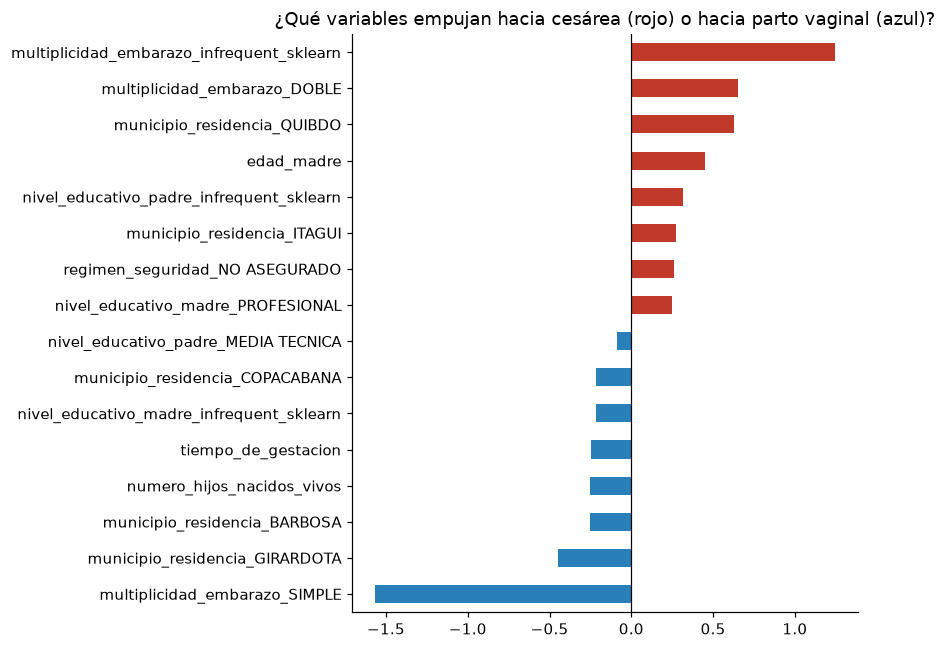

nivel_educativo_padre_infrequent_sklearn     0.32
edad_madre                                   0.45
municipio_residencia_QUIBDO                  0.63
multiplicidad_embarazo_DOBLE                 0.65
multiplicidad_embarazo_infrequent_sklearn    1.25

multiplicidad_embarazo_SIMPLE    -1.57
municipio_residencia_GIRARDOTA   -0.45
municipio_residencia_BARBOSA     -0.25
numero_hijos_nacidos_vivos       -0.25
tiempo_de_gestacion              -0.24


In [20]:
nombres = logistica.named_steps["prep"].get_feature_names_out()
coef = pd.Series(logistica.named_steps["clf"].coef_[0], index=[n.split("__", 1)[1] for n in nombres]).sort_values()
top = pd.concat([coef.head(8), coef.tail(8)])
fig, ax = plt.subplots(figsize=(8, 6))
top.plot.barh(ax=ax, color=["#2980b9" if v < 0 else "#c0392b" for v in top])
ax.axvline(0, color="k", lw=.8)
ax.set_title("¿Qué variables empujan hacia cesárea (rojo) o hacia parto vaginal (azul)?")
plt.tight_layout(); plt.show()
print(coef.tail(5).round(2).to_string()); print(); print(coef.head(5).round(2).to_string())

### 4.4 El umbral y el cambio de régimen

La proporción de cesáreas del conjunto de prueba es mayor que la del entrenamiento (ver 4.1 y gráfico G1). Eso afecta cómo se lee cada métrica. Se revisa el efecto del umbral sobre el recall.

In [21]:
proba = logistica.predict_proba(X_te)[:, 1]
filas = []
for u in [0.3, 0.4, 0.5, 0.6]:
    p = (proba >= u).astype(int)
    filas.append({"umbral": u, "precisión": precision_score(y_te, p, zero_division=0),
                  "recall": recall_score(y_te, p), "F1": f1_score(y_te, p)})
pd.DataFrame(filas).set_index("umbral").round(3)

,precisión,recall,F1
umbral,,,
0.3,0.500,0.639,0.561
0.4,0.616,0.341,0.439
0.5,0.705,0.165,0.268
0.6,0.846,0.095,0.170


## 5. Conclusiones y límites

**Resultados en la prueba (2025–2026, 8 337 partos, 39,5 % cesárea):**

| Modelo | Exactitud | Precisión | Recall cesárea | F1 cesárea | AUC |
| --- | --- | --- | --- | --- | --- |
| Nulo (siempre parto vaginal) | 0,605 | 0,00 | 0,00 | 0,00 | 0,50 |
| Regresión logística | 0,643 | 0,71 | 0,17 | 0,27 | 0,65 |
| Bosque aleatorio | 0,635 | 0,81 | 0,10 | 0,18 | 0,66 |

1. **¿Gana el modelo al nulo? Sí, pero por poco.** La exactitud sube de 0,605 a 0,643 y el AUC de 0,50 a 0,65. El nulo no detecta ninguna cesárea; la logística detecta el 17 % con el umbral por defecto. Es una mejora real pero modesta: con estos predictores no se puede anticipar bien una cesárea individual.
2. **El umbral cambia mucho la lectura.** Bajando el umbral de 0,5 a 0,3 el recall pasa de 0,17 a 0,64 (precisión 0,50, F1 0,56). El modelo "por defecto" se queda corto porque fue entrenado cuando las cesáreas eran el 31,9 % y se prueba cuando son el 39,5 %.
3. **El patrón tiene sentido en el dominio:**
   - **Embarazo múltiple:** 86 % de cesáreas en dobles (y 15 de 15 en triples) frente a 33 % en simples. Es el predictor más fuerte, aunque afecta a pocos partos (~3 %).
   - **Edad de la madre:** la tasa sube de 22 % en menores de 18 a 52 % en mayores de 40.
   - **Régimen:** subsidiado 33 %, contributivo 39 %, excepción 45 %. Hay diferencia, pero mezcla perfil de riesgo con tipo de atención, así que no se interpreta como causa.
4. **Cambio de régimen.** La proporción de cesáreas sube de ~28 % (2022) a ~42 % (2026), como muestra el primer gráfico. Parte puede ser composición de pacientes o cambios en el registro; los datos no permiten separarlo.
5. **El bosque no mejora a la logística** (F1 0,18 frente a 0,27): no justifica su opacidad.

**Lo que NO se puede concluir:**
- Que el modelo sirva para decidir o auditar cesáreas individuales: las **indicaciones clínicas** (cesárea previa, presentación fetal, sufrimiento fetal, preeclampsia) **no están en la base**, y son lo que más pesa en la decisión. Eso fija un techo bajo al rendimiento.
- Que los resultados valgan para Antioquia o Colombia: es **un solo hospital**, y uno de referencia, con más casos complejos que un hospital promedio.
- Que `regimen_seguridad` o el municipio *causen* más cesáreas. Los coeficientes de municipios pequeños (por ejemplo Quibdó) se apoyan en pocos casos.
- Nada sobre el último trimestre como tendencia: 2026 llega solo hasta septiembre.

**Calidad del dato (qué se arregló):** tildes distintas entre periodos (`CESAREA`/`CESÁREA`), redacción cambiante del estado civil (13 → 6 categorías), `SIN INFORMACION` tratado como faltante, 3 edades de padre imposibles pasadas a `NaN`, y `localidad` descartada por tener un hueco estructural. No se eliminó ninguna fila.